# [Projekt 1](https://leon.pw.edu.pl/mod/assign/view.php?id=14888): klasyfikacja i regresja z użyciem perceptronu (20 punktów)

## 2.1. Część pierwsza (15 punktów)

Program pozwalający rozwiązywać zadania klasyfikacji i regresji z użyciem perceptronu wielowarstwowego oraz wizualizujący jego działanie, w tym uczenie sieci z użyciem algorytmu propagacji wstecznej błędu (SGD lub jego wariantów).

Wymagane są wizualizacje:

- wyników uczenia sieci dla problemu regresji dla funkcji \(\mathbb{R} \to \mathbb{R}\) oraz problemu klasyfikacji wektorów w \(\mathbb{R}^2\);
- przebiegu błędu w kolejnych iteracjach;
- ewolucji wartości wag.

### 2.1.1. Zbiory danych

Na początku zajęć udostępniony będzie zestaw zbiorów danych, na których należy przeprowadzić eksperymenty badające skuteczność działania sieci.

### 2.1.2. Uwagi do implementacji

Implementację należy wykonać na poziomie podstawowym, tak aby kod pokazywał zrozumienie zasad działania i uczenia sieci. **Nie można korzystać z bibliotek implementujących sieci neuronowe.** Można korzystać z biblioteki *NumPy*.

### 2.1.3. Elementy do zaimplementowania

- możliwość zainicjowania powtarzalnego procesu uczenia z zadanym ziarnem generatora liczb losowych;
- łatwa konfiguracja liczby warstw i neuronów w warstwie oraz obecności biasów;
- wizualizacja zbioru uczącego i efektów klasyfikacji oraz regresji;
- wizualizacja błędu propagowanego w kolejnych iteracjach uczenia;
- wizualizacja wartości wag w kolejnych iteracjach uczenia.

### 2.1.4. Elementy do zbadania

- **Wpływ funkcji aktywacji na skuteczność działania sieci** – sprawdzić funkcję sigmoidalną i dwie inne wybrane funkcje aktywacji wewnątrz sieci. Funkcję aktywacji na wyjściu należy dobrać odpowiednio do rodzaju problemu.
- **Wpływ liczby warstw ukrytych i ich liczności** – zbadać różne liczby warstw, od 0 do 4, oraz kilka różnych architektur.
- **Wpływ miary błędu na skuteczność uczenia** – sprawdzić dwie miary błędu dla klasyfikacji i dwie dla regresji.

Wyniki i wnioski należy koniecznie opisać w raporcie z projektu.

## 2.2. Część druga (5 punktów)

Z użyciem implementacji wytworzonej w części pierwszej, modyfikując jedynie parametry sieci (liczbę warstw, neuronów, funkcję aktywacji itp.), ale nie rozszerzając implementacji o nowe funkcjonalności, należy nauczyć sieć rozpoznawać cyfry ze zbioru MNIST. Można modyfikować kod programu w celu jego zoptymalizowania, na przykład przez użycie tablic zamiast obiektów.

W procesie uczenia sieci korzystamy **wyłącznie ze zbioru oznaczonego jako uczący**. Zbiór testowy wykorzystujemy wyłącznie do oceny jakości już nauczonej sieci.

Sieć zgłoszona do oceny wyników musi umożliwiać powtórzenie procesu uczenia. Oznacza to, że należy dostarczyć wszystkie niezbędne parametry programu do ponownego uczenia. Jeśli uczenie korzysta z generatora liczb pseudolosowych, należy również dostarczyć ziarno generatora, aby można było dokładnie powtórzyć proces uczenia.

> **Uwaga:** Uczenie na dużym zbiorze zajmuje odpowiednio dużo czasu. We wstępnych eksperymentach można wybrać podzbiór danych uczących i uczyć tylko na nim, a dopiero po wstępnym rozpoznaniu przeprowadzić pełne uczenie.

# Eksperymenty - Część pierwsza

In [1]:
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from data import load_classification, load_mnist, load_regression, standardize
from mlp import MLP, sigmoid, tanh, relu, linear, softmax, mse, mae, cross_entropy
from plots import ACT_COLORS, LINE_SERIES, SERIES, plot_data_cls, plot_data_reg, plot_decision, plot_loss, plot_reg_fit, plot_network, plot_weights, plot_digits, plot_confusion

DATA = "data/projekt1"
SIZE = 1000
LR = 0.1
BATCH = 32
EPOCHS_REG = 1000
EPOCHS_CLS = 300
SEEDS = [0, 1, 2]

ACTIVATIONS = {"sigmoid": sigmoid, "tanh": tanh, "relu": relu}
REG_SETS = ["cube", "activation"]
CLS_SETS = ["simple", "three_gauss"]

os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

## Funkcje pomocnicze

In [2]:
def load_reg(name):
    X_train, Y_train = load_regression(f"{DATA}/regression/data.{name}.train.{SIZE}.csv")
    X_test, Y_test = load_regression(f"{DATA}/regression/data.{name}.test.{SIZE}.csv")
    X_train_n, X_test_n, x_mean, x_std = standardize(X_train, X_test)
    Y_train_n, Y_test_n, y_mean, y_std = standardize(Y_train, Y_test)
    return dict(name=name, X_train=X_train, Y_train=Y_train, X_test=X_test, Y_test=Y_test,
                X_train_n=X_train_n, Y_train_n=Y_train_n, X_test_n=X_test_n,
                x_mean=x_mean, x_std=x_std, y_mean=y_mean, y_std=y_std)


def load_cls(name):
    X_train, Y_train = load_classification(f"{DATA}/classification/data.{name}.train.{SIZE}.csv")
    X_test, Y_test = load_classification(f"{DATA}/classification/data.{name}.test.{SIZE}.csv")
    return dict(name=name, X_train=X_train, Y_train=Y_train, X_test=X_test, Y_test=Y_test)


reg_data = {name: load_reg(name) for name in REG_SETS}
cls_data = {name: load_cls(name) for name in CLS_SETS}
for d in [*reg_data.values(), *cls_data.values()]:
    print(f"{d['name']:12} train X {d['X_train'].shape}  Y {d['Y_train'].shape}   test X {d['X_test'].shape}")

cube         train X (1, 1000)  Y (1, 1000)   test X (1, 1201)
activation   train X (1, 1000)  Y (1, 1000)   test X (1, 1201)
simple       train X (2, 1000)  Y (2, 1000)   test X (2, 1000)
three_gauss  train X (2, 3000)  Y (3, 3000)   test X (2, 3000)


In [3]:
def train_reg(d, hidden, activation, loss=mse, seed=0, epochs=EPOCHS_REG, use_bias=True):
    net = MLP([1, *hidden, 1], activation, linear, loss, seed, use_bias)
    history = net.train(d["X_train_n"], d["Y_train_n"], epochs, LR, BATCH)
    return net, history


def train_cls(d, hidden, activation, output=softmax, loss=cross_entropy, seed=0, epochs=EPOCHS_CLS, use_bias=True):
    K = d["Y_train"].shape[0]
    net = MLP([2, *hidden, K], activation, output, loss, seed, use_bias)
    history = net.train(d["X_train"], d["Y_train"], epochs, LR, BATCH)
    return net, history


def predict_reg(net, d, X_n):
    # network output scaled back to the original units
    return net.predict(X_n) * d["y_std"] + d["y_mean"]


def rmse(pred, Y):
    return np.sqrt(np.mean((pred - Y) ** 2))


def reg_metrics(net, d):
    in_range = (d["X_test"] >= d["X_train"].min()) & (d["X_test"] <= d["X_train"].max())
    pred_test = predict_reg(net, d, d["X_test_n"])
    return {
        "RMSE train": rmse(predict_reg(net, d, d["X_train_n"]), d["Y_train"]),
        "RMSE test (train x-range)": rmse(pred_test[in_range], d["Y_test"][in_range]),
        "RMSE test (all)": rmse(pred_test, d["Y_test"]),
    }


def accuracy(net, X, Y):
    return np.mean(net.predict(X).argmax(axis=0) == Y.argmax(axis=0))


def cls_metrics(net, d):
    return {"accuracy train": accuracy(net, d["X_train"], d["Y_train"]),
            "accuracy test": accuracy(net, d["X_test"], d["Y_test"])}


def summarize(rows, by):
    # mean over seeds
    return pd.DataFrame(rows).drop(columns="seed").groupby(by, sort=False).mean()

In [4]:
def show_fit(ax, net, d, title, color):
    predict = lambda x: predict_reg(net, d, (x - d["x_mean"]) / d["x_std"])
    plot_reg_fit(ax, predict, d["X_train"], d["Y_train"], d["X_test"], d["Y_test"], title, color)


def show_regions(ax, net, d, title):
    plot_decision(ax, net, d["X_train"], d["Y_train"], title)

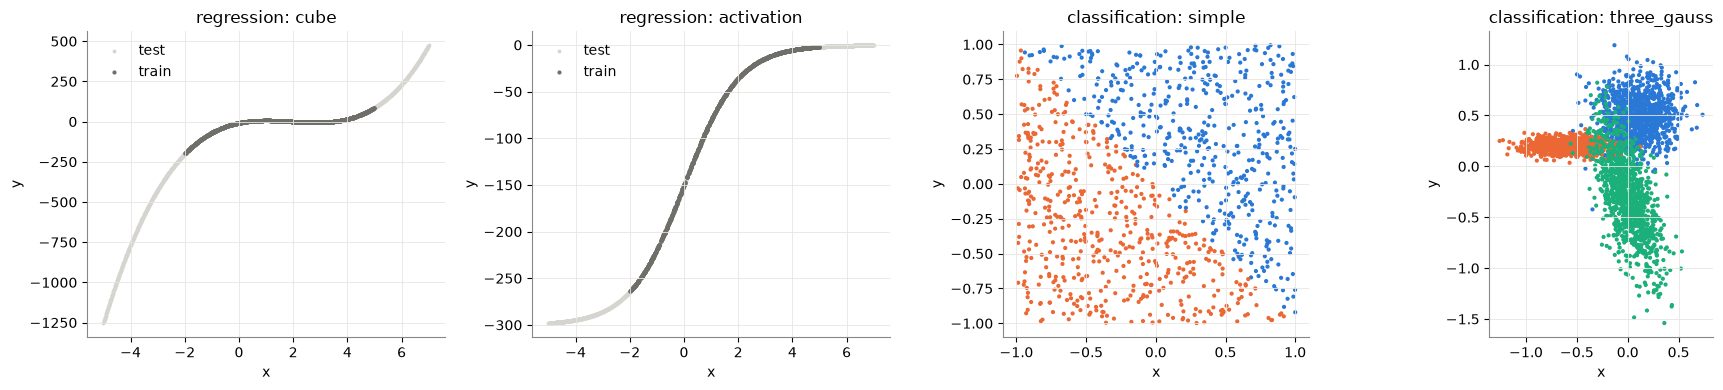

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, d in zip(axes[:2], reg_data.values()):
    plot_data_reg(ax, d["X_train"], d["Y_train"], d["X_test"], d["Y_test"])
    ax.set_title(f"regression: {d['name']}")
    ax.legend()
for ax, d in zip(axes[2:], cls_data.values()):
    plot_data_cls(ax, d["X_train"], d["Y_train"])
    ax.set_title(f"classification: {d['name']}")
fig.tight_layout()
fig.savefig("figures/datasets.png")
plt.show()

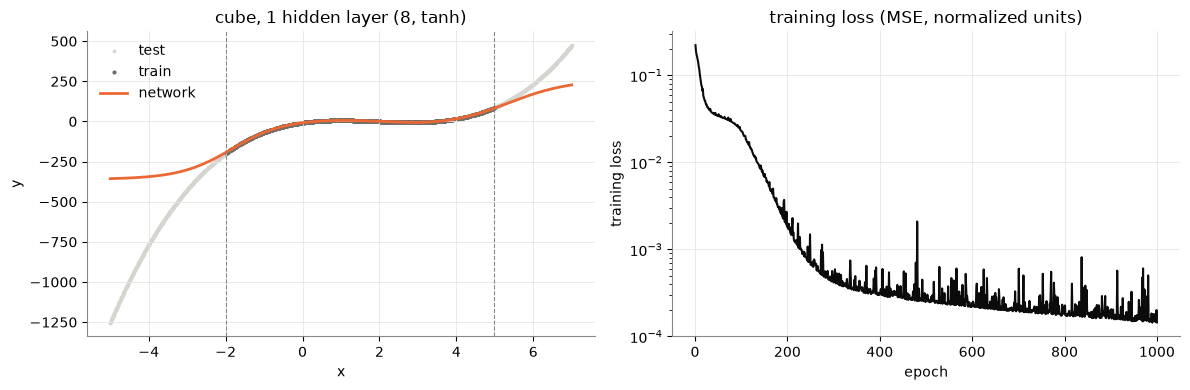

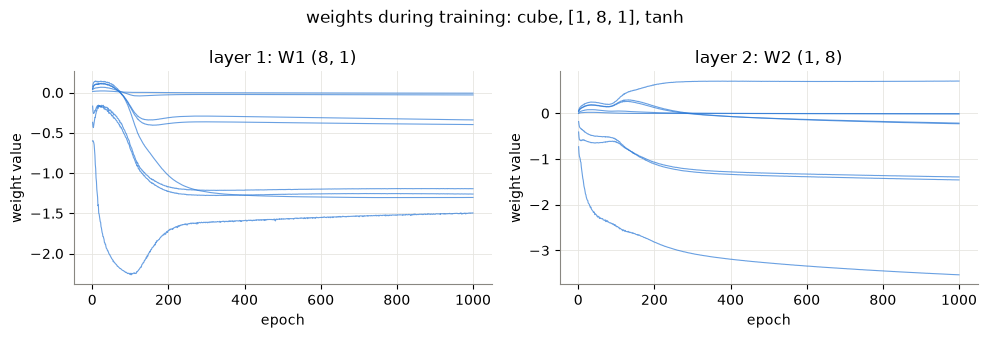

{'RMSE train': np.float64(0.8753663480270298), 'RMSE test (train x-range)': np.float64(0.9329218443218638), 'RMSE test (all)': np.float64(212.6401156487309)}


In [6]:
d = reg_data["cube"]
net, history = train_reg(d, [8], tanh, seed=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
show_fit(axes[0], net, d, "cube, 1 hidden layer (8, tanh)", ACT_COLORS["tanh"])
axes[0].legend()
plot_loss(axes[1], history)
axes[1].set_title("training loss (MSE, normalized units)")
fig.tight_layout()
fig.savefig("figures/demo_regression.png")
plt.show()

plot_weights(history, "weights during training: cube, [1, 8, 1], tanh").savefig("figures/demo_regression_weights.png")
plt.show()
print(reg_metrics(net, d))

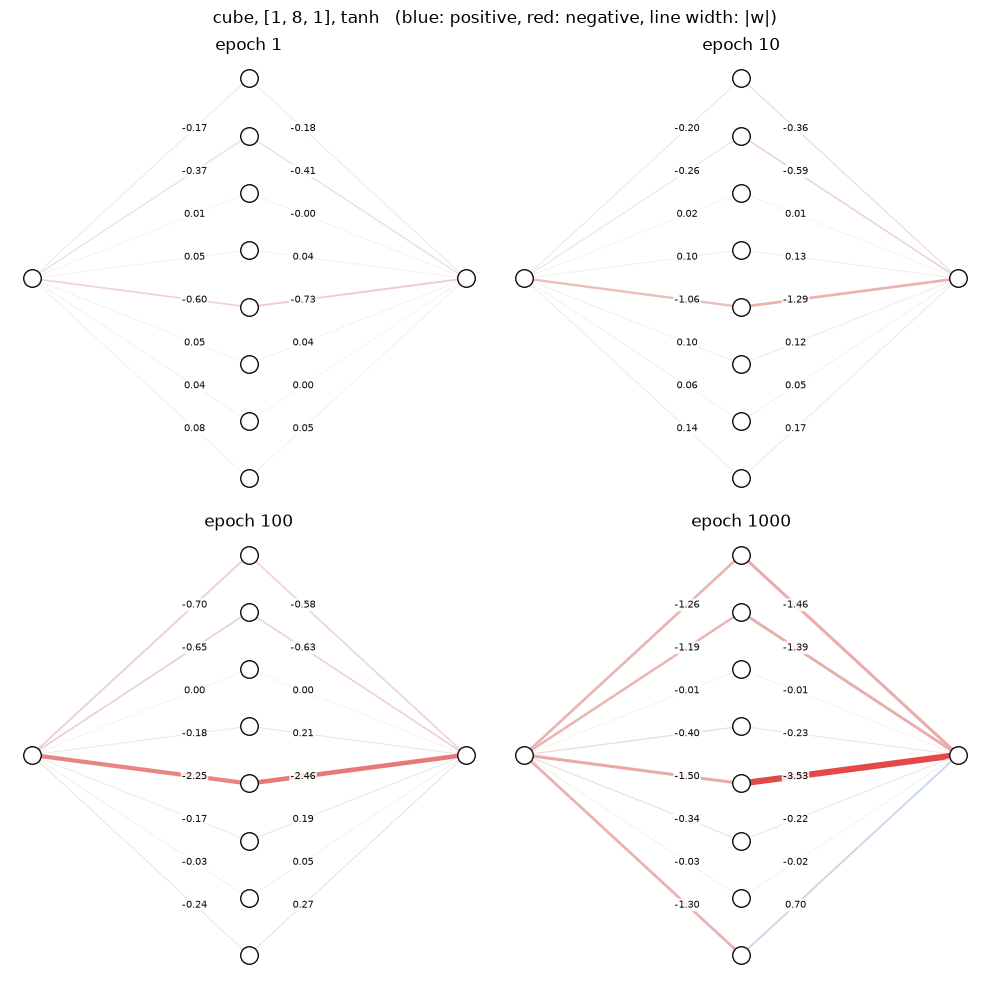

In [ ]:
plot_network(history, [1, 10, 100, EPOCHS_REG], "cube, [1, 8, 1], tanh").savefig("figures/demo_regression_network.png")
plt.show()

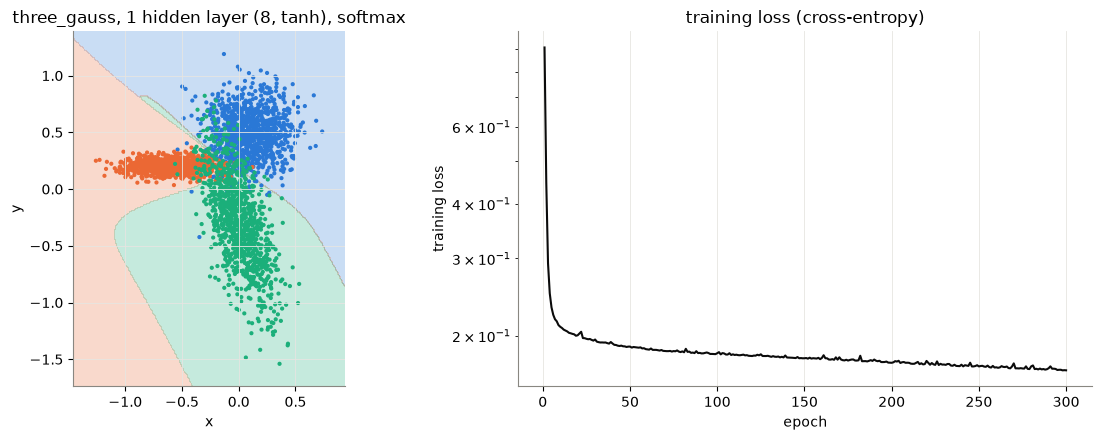

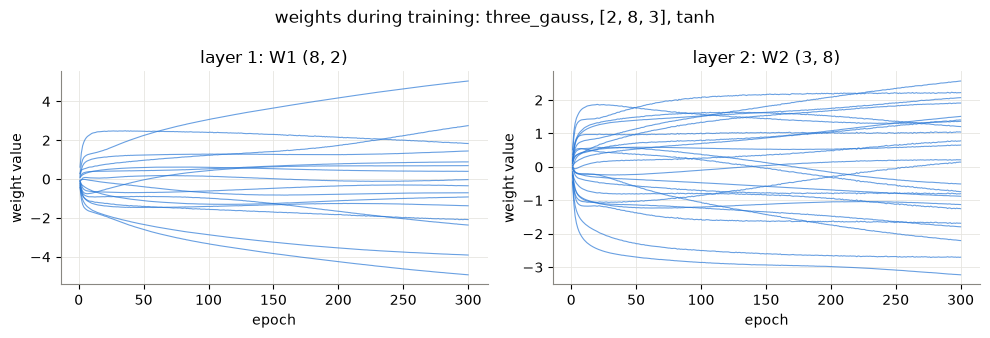

{'accuracy train': np.float64(0.932), 'accuracy test': np.float64(0.9316666666666666)}


In [7]:
d = cls_data["three_gauss"]
net, history = train_cls(d, [8], tanh, seed=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
show_regions(axes[0], net, d, "three_gauss, 1 hidden layer (8, tanh), softmax")
plot_loss(axes[1], history)
axes[1].set_title("training loss (cross-entropy)")
fig.tight_layout()
fig.savefig("figures/demo_classification.png")
plt.show()

plot_weights(history, "weights during training: three_gauss, [2, 8, 3], tanh").savefig("figures/demo_classification_weights.png")
plt.show()
print(cls_metrics(net, d))

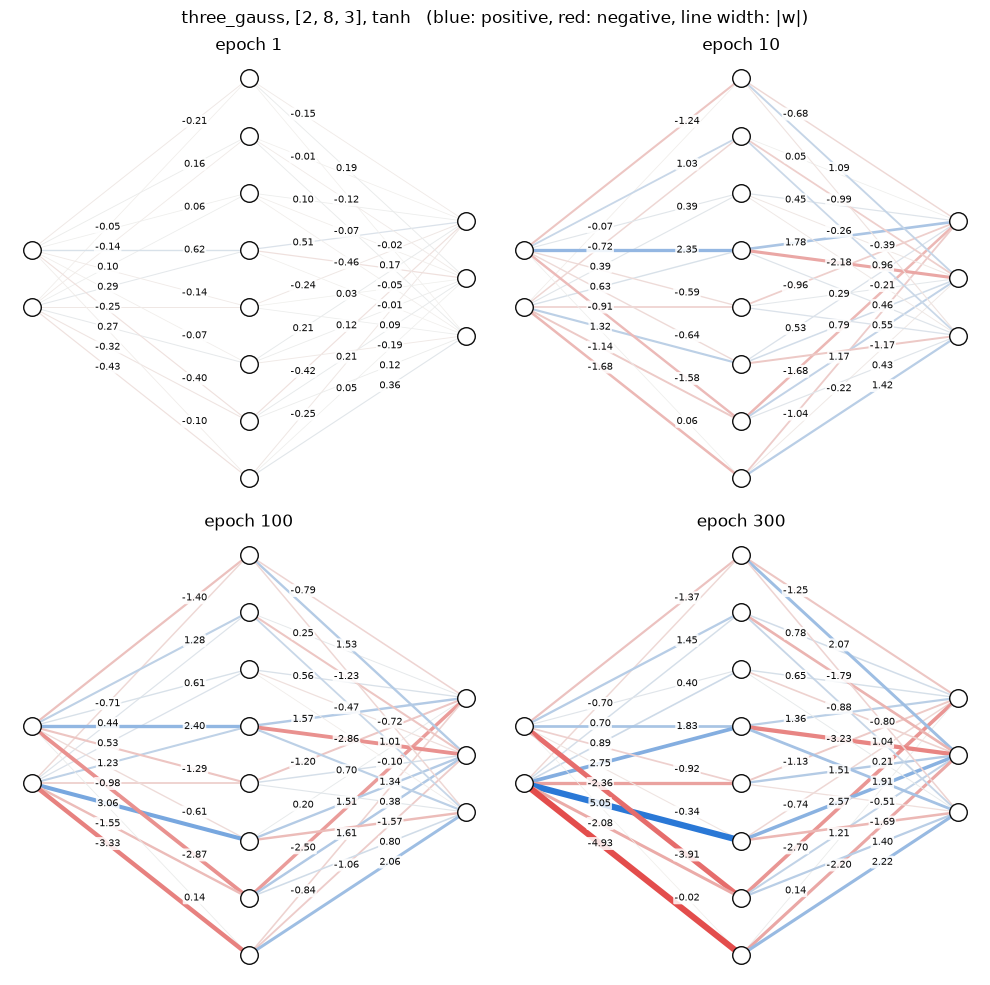

In [ ]:
plot_network(history, [1, 10, 100, EPOCHS_CLS], "three_gauss, [2, 8, 3], tanh").savefig("figures/demo_classification_network.png")
plt.show()

### Biasy włączone / wyłączone

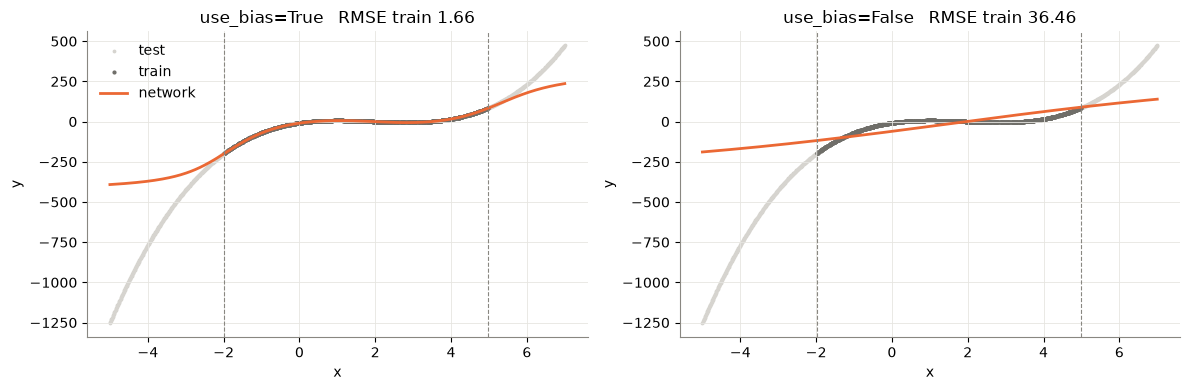

In [8]:
d = reg_data["cube"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, use_bias in zip(axes, [True, False]):
    net, _ = train_reg(d, [10, 10], tanh, seed=0, use_bias=use_bias)
    m = reg_metrics(net, d)
    show_fit(ax, net, d, f"use_bias={use_bias}   RMSE train {m['RMSE train']:.2f}", ACT_COLORS["tanh"])
axes[0].legend()
fig.tight_layout()
fig.savefig("figures/demo_bias.png")
plt.show()

## Eksperyment 1: funkcja aktywacji

2 warstwy ukryte \* 10 neuronów, z funkcją sigmoidalną, tanh, ReLU. Wyjście: liniowe (regresja),
softmax + entropia krzyżowa (klasyfikacja).

In [9]:
E1_HIDDEN = [10, 10]
rows_reg, rows_cls, e1_runs = [], [], {}
start = time.time()
for name, d in reg_data.items():
    for act_name, act in ACTIVATIONS.items():
        for seed in SEEDS:
            net, history = train_reg(d, E1_HIDDEN, act, seed=seed)
            rows_reg.append({"dataset": name, "activation": act_name, "seed": seed, **reg_metrics(net, d)})
            if seed == SEEDS[0]:
                e1_runs[name, act_name] = net, history
for name, d in cls_data.items():
    for act_name, act in ACTIVATIONS.items():
        for seed in SEEDS:
            net, history = train_cls(d, E1_HIDDEN, act, seed=seed)
            rows_cls.append({"dataset": name, "activation": act_name, "seed": seed, **cls_metrics(net, d)})
            if seed == SEEDS[0]:
                e1_runs[name, act_name] = net, history
print(f"{time.time() - start:.0f} s")

e1_reg = summarize(rows_reg, ["dataset", "activation"])
e1_cls = summarize(rows_cls, ["dataset", "activation"])
e1_reg.to_csv("results/e1_activation_regression.csv")
e1_cls.to_csv("results/e1_activation_classification.csv")
display(e1_reg.round(2), e1_cls.round(4))

29 s


RMSE train  RMSE test (train x-range)  RMSE test (all)
dataset    activation                                                        
cube       sigmoid           1.93                       2.03           215.77
           tanh              0.99                       1.01           204.17
           relu              2.89                       2.92           182.05
activation sigmoid           0.61                       0.62             3.61
           tanh              0.42                       0.42             1.49
           relu              0.63                       0.65            23.24

accuracy train  accuracy test
dataset     activation                               
simple      sigmoid             0.9973         0.9953
            tanh                0.9923         0.9897
            relu                0.9923         0.9893
three_gauss sigmoid             0.9312         0.9286
            tanh                0.9344         0.9359
            relu                0.9359         0.9338

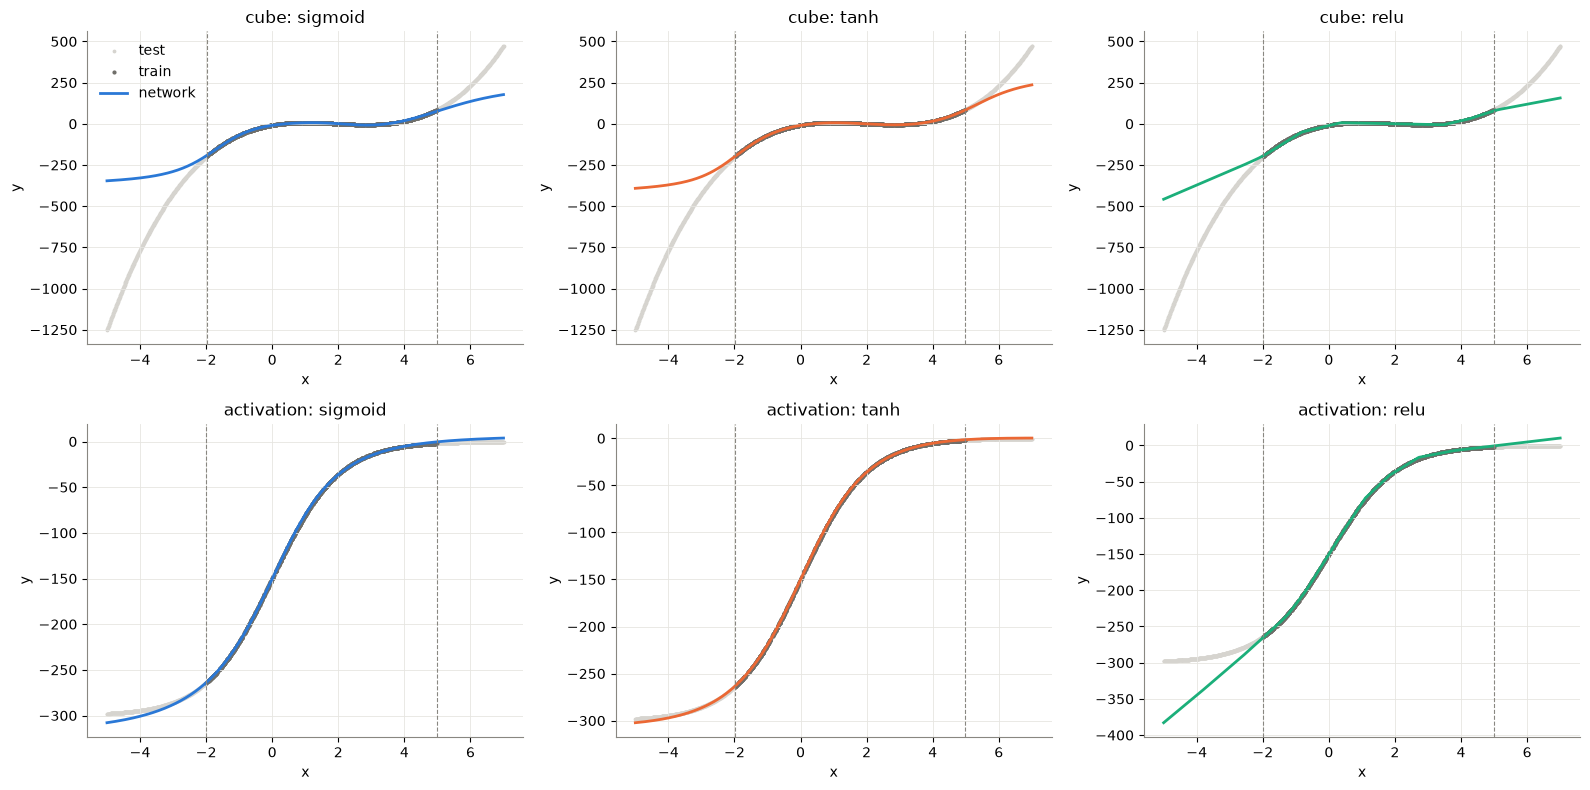

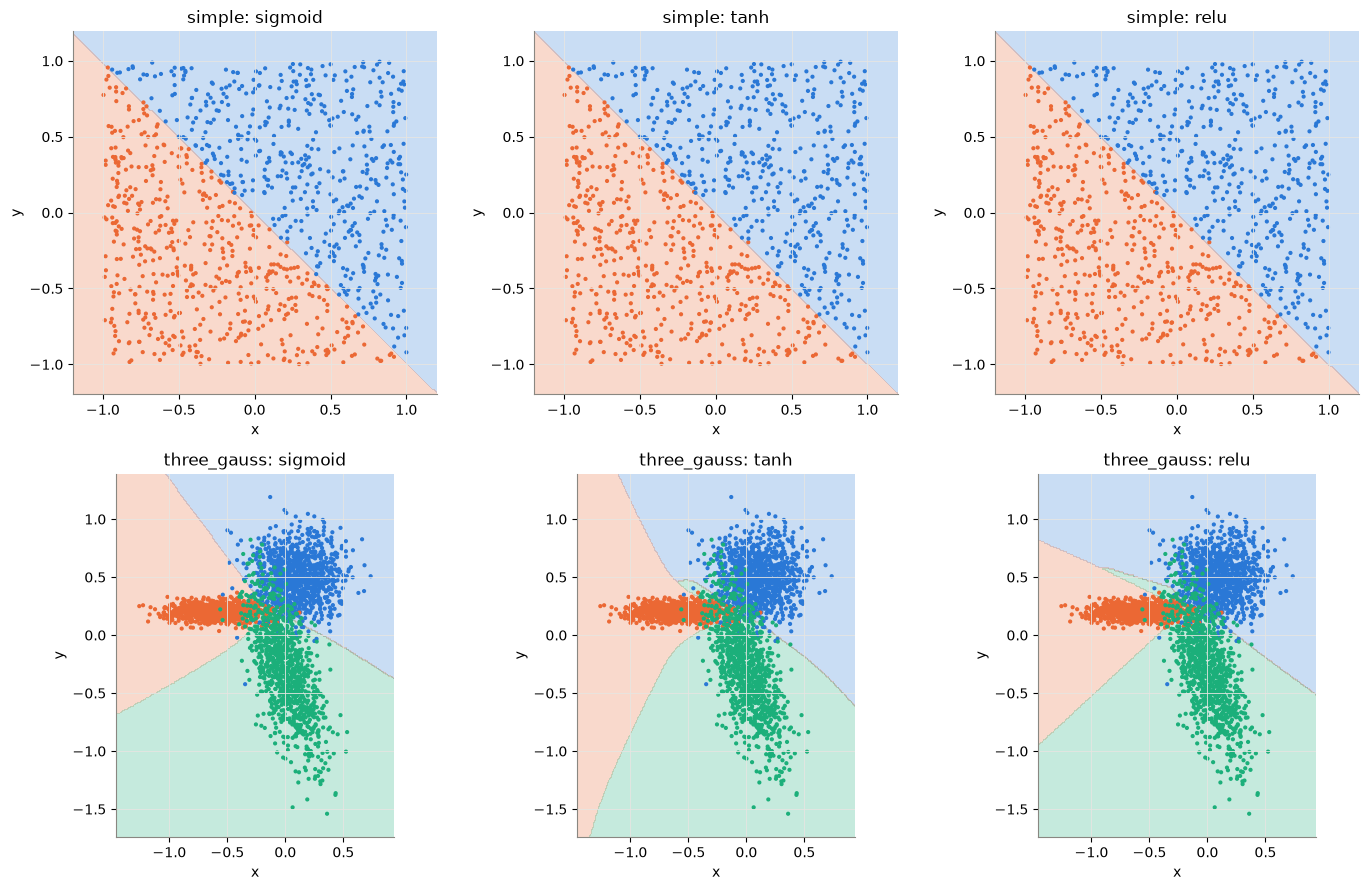

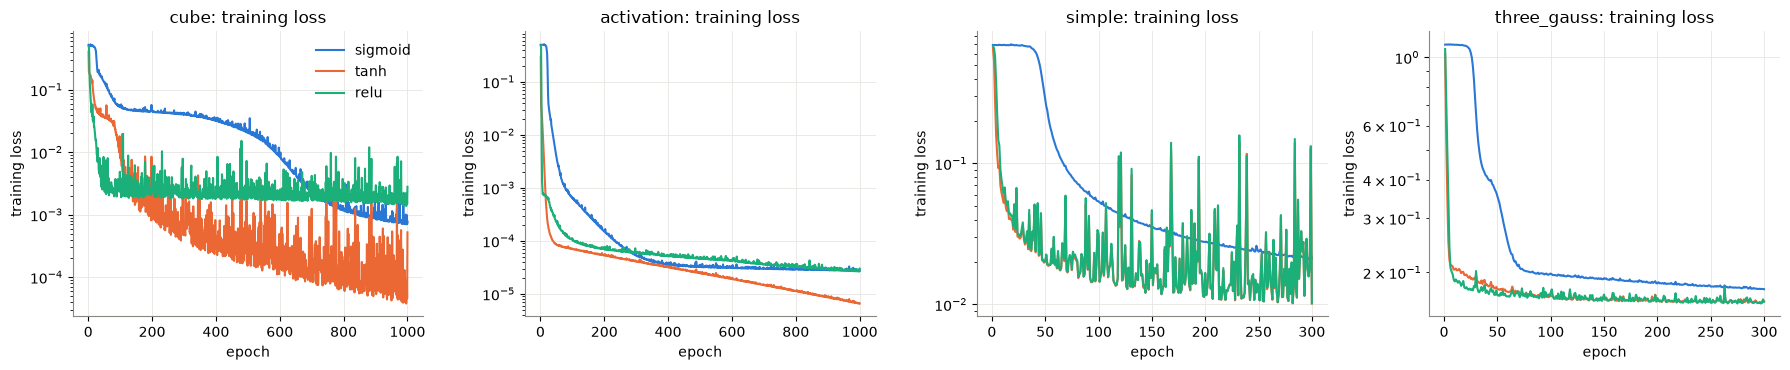

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for row, name in zip(axes, REG_SETS):
    for ax, act_name in zip(row, ACTIVATIONS):
        show_fit(ax, e1_runs[name, act_name][0], reg_data[name], f"{name}: {act_name}", color=ACT_COLORS[act_name])
axes[0, 0].legend()
fig.tight_layout()
fig.savefig("figures/e1_regression_fits.png")
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(14, 9))
for row, name in zip(axes, CLS_SETS):
    for ax, act_name in zip(row, ACTIVATIONS):
        show_regions(ax, e1_runs[name, act_name][0], cls_data[name], f"{name}: {act_name}")
fig.tight_layout()
fig.savefig("figures/e1_decision_regions.png")
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, name in zip(axes, REG_SETS + CLS_SETS):
    for act_name in ACTIVATIONS:
        plot_loss(ax, e1_runs[name, act_name][1], label=act_name, color=ACT_COLORS[act_name])
    ax.set_title(f"{name}: training loss")
axes[0].legend()
fig.tight_layout()
fig.savefig("figures/e1_loss_curves.png")
plt.show()

## Eksperyment 2: liczba warstw ukrytych i ich liczność

0–4 warstwy ukryte * 10 neuronów oraz architektury 1\*3, 1\*50 i 2\*50, każda z trzema funkcjami aktywacji.

In [11]:
ARCHITECTURES = {
    "0 hidden": [],
    "1×3": [3], "1×10": [10], "1×50": [50],
    "2×10": [10, 10], "2×50": [50, 50],
    "3×10": [10, 10, 10],
    "4×10": [10, 10, 10, 10],
}
rows_reg, rows_cls, e2_runs = [], [], {}
start = time.time()
for arch, hidden in ARCHITECTURES.items():
    for act_name, act in ACTIVATIONS.items():
        for seed in SEEDS:
            for name, d in reg_data.items():
                net, history = train_reg(d, hidden, act, seed=seed)
                rows_reg.append({"dataset": name, "architecture": arch, "activation": act_name, "seed": seed, **reg_metrics(net, d)})
                if seed == SEEDS[0]:
                    e2_runs[name, arch, act_name] = net, history
            for name, d in cls_data.items():
                net, history = train_cls(d, hidden, act, seed=seed)
                rows_cls.append({"dataset": name, "architecture": arch, "activation": act_name, "seed": seed, **cls_metrics(net, d)})
                if seed == SEEDS[0]:
                    e2_runs[name, arch, act_name] = net, history
print(f"{time.time() - start:.0f} s")

e2_reg = summarize(rows_reg, ["dataset", "architecture", "activation"])
e2_cls = summarize(rows_cls, ["dataset", "architecture", "activation"])
e2_reg.to_csv("results/e2_architecture_regression.csv")
e2_cls.to_csv("results/e2_architecture_classification.csv")


def by_architecture(table, metric):
    return table[metric].unstack(["dataset", "activation"]).reindex(list(ARCHITECTURES))


print("RMSE on the test set inside the training x-range (interpolation):")
display(by_architecture(e2_reg, "RMSE test (train x-range)").round(2))
print("RMSE on the whole test set (mostly extrapolation):")
display(by_architecture(e2_reg, "RMSE test (all)").round(1))
print("test accuracy:")
display(by_architecture(e2_cls, "accuracy test").round(4))

238 s
RMSE on the test set inside the training x-range (interpolation):


dataset,cube,activation,cube,activation,cube,activation
activation,sigmoid,sigmoid,tanh,tanh,relu,relu
architecture,,,,,,
0 hidden,31.43,26.57,31.43,26.57,31.43,26.57
1×3,3.97,0.22,1.03,0.17,32.83,39.79
1×10,7.61,0.41,1.01,0.11,2.45,1.53
1×50,13.84,0.47,1.79,0.09,0.43,0.62
2×10,2.03,0.62,1.01,0.42,2.92,0.65
2×50,1.26,0.58,1.30,0.15,0.32,0.22
3×10,12.74,0.71,0.62,0.68,1.44,0.45
4×10,52.87,88.12,0.73,0.77,1.25,0.46


RMSE on the whole test set (mostly extrapolation):


dataset,cube,activation,cube,activation,cube,activation
activation,sigmoid,sigmoid,tanh,tanh,relu,relu
architecture,,,,,,
0 hidden,306.0,48.6,306.0,48.6,306.0,48.6
1×3,249.2,0.5,217.4,0.4,299.1,75.5
1×10,261.3,1.1,210.8,0.4,162.9,36.6
1×50,255.8,1.0,186.9,0.7,142.6,31.6
2×10,215.8,3.6,204.2,1.5,182.0,23.2
2×50,202.6,10.2,197.8,1.0,162.9,24.4
3×10,249.0,4.2,222.2,2.2,201.2,19.1
4×10,364.9,124.5,234.6,2.3,194.1,18.2


test accuracy:


dataset,simple,three_gauss,simple,three_gauss,simple,three_gauss
activation,sigmoid,sigmoid,tanh,tanh,relu,relu
architecture,,,,,,
0 hidden,0.9967,0.9243,0.9967,0.9243,0.9967,0.9243
1×3,0.9967,0.9268,0.9947,0.9311,0.9947,0.9312
1×10,0.9963,0.9267,0.9947,0.9330,0.9947,0.9342
1×50,0.9957,0.9259,0.9960,0.9321,0.9957,0.9360
2×10,0.9953,0.9286,0.9897,0.9359,0.9893,0.9338
2×50,0.9937,0.9276,0.9927,0.9363,0.9930,0.9354
3×10,0.4973,0.5151,0.9937,0.9350,0.9940,0.9350
4×10,0.4920,0.3333,0.9840,0.9338,0.8250,0.9333


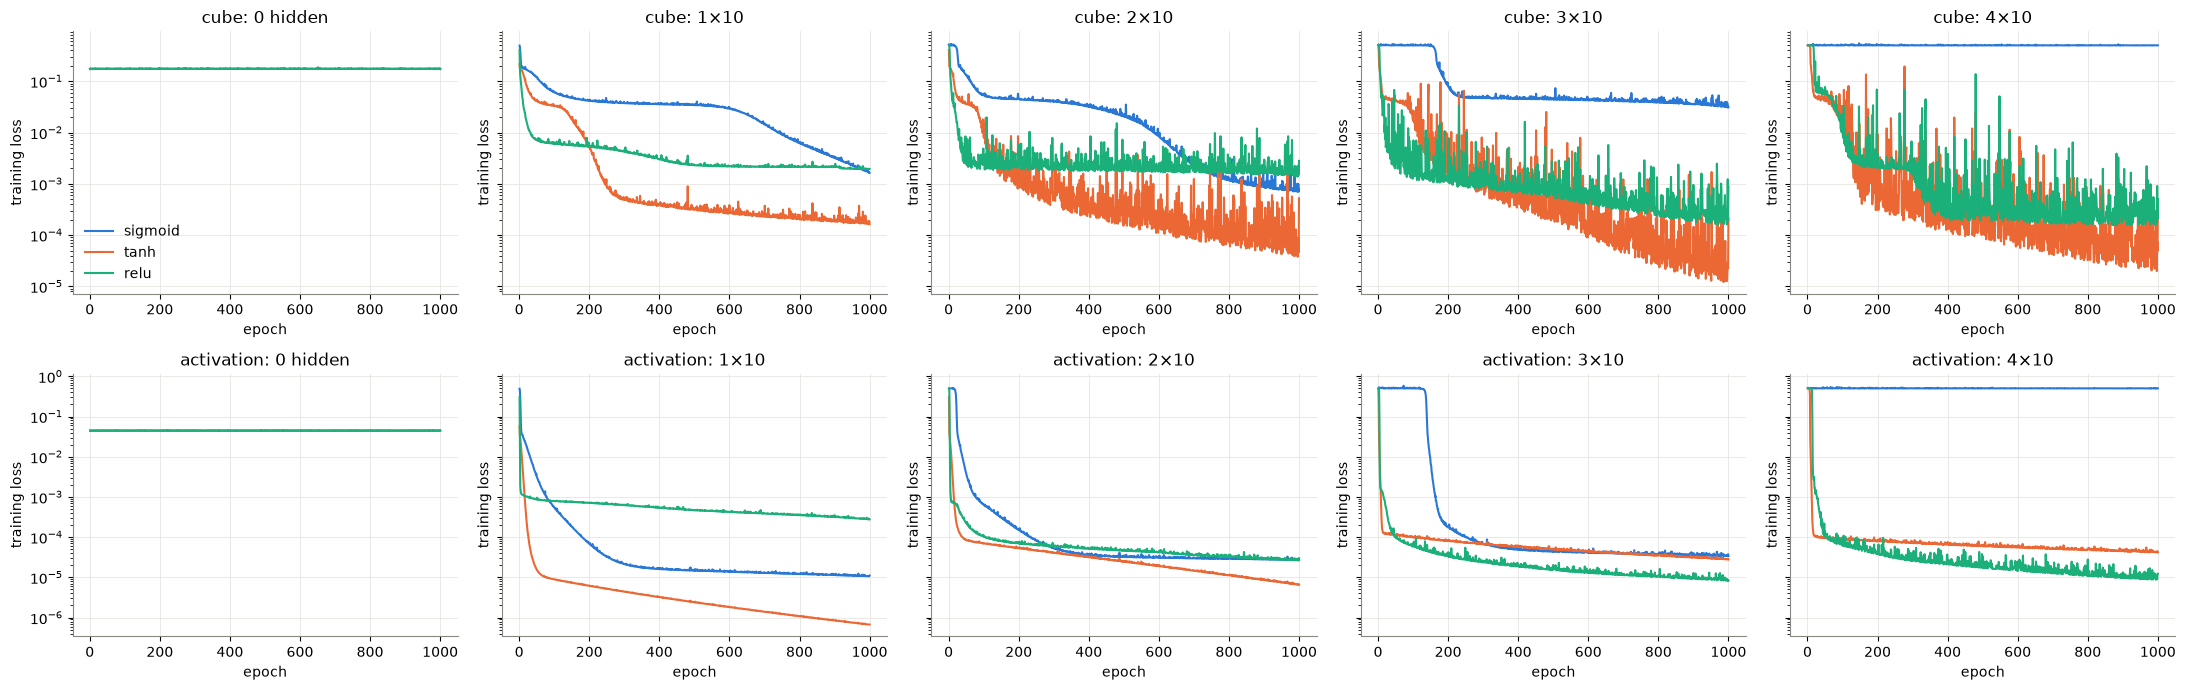

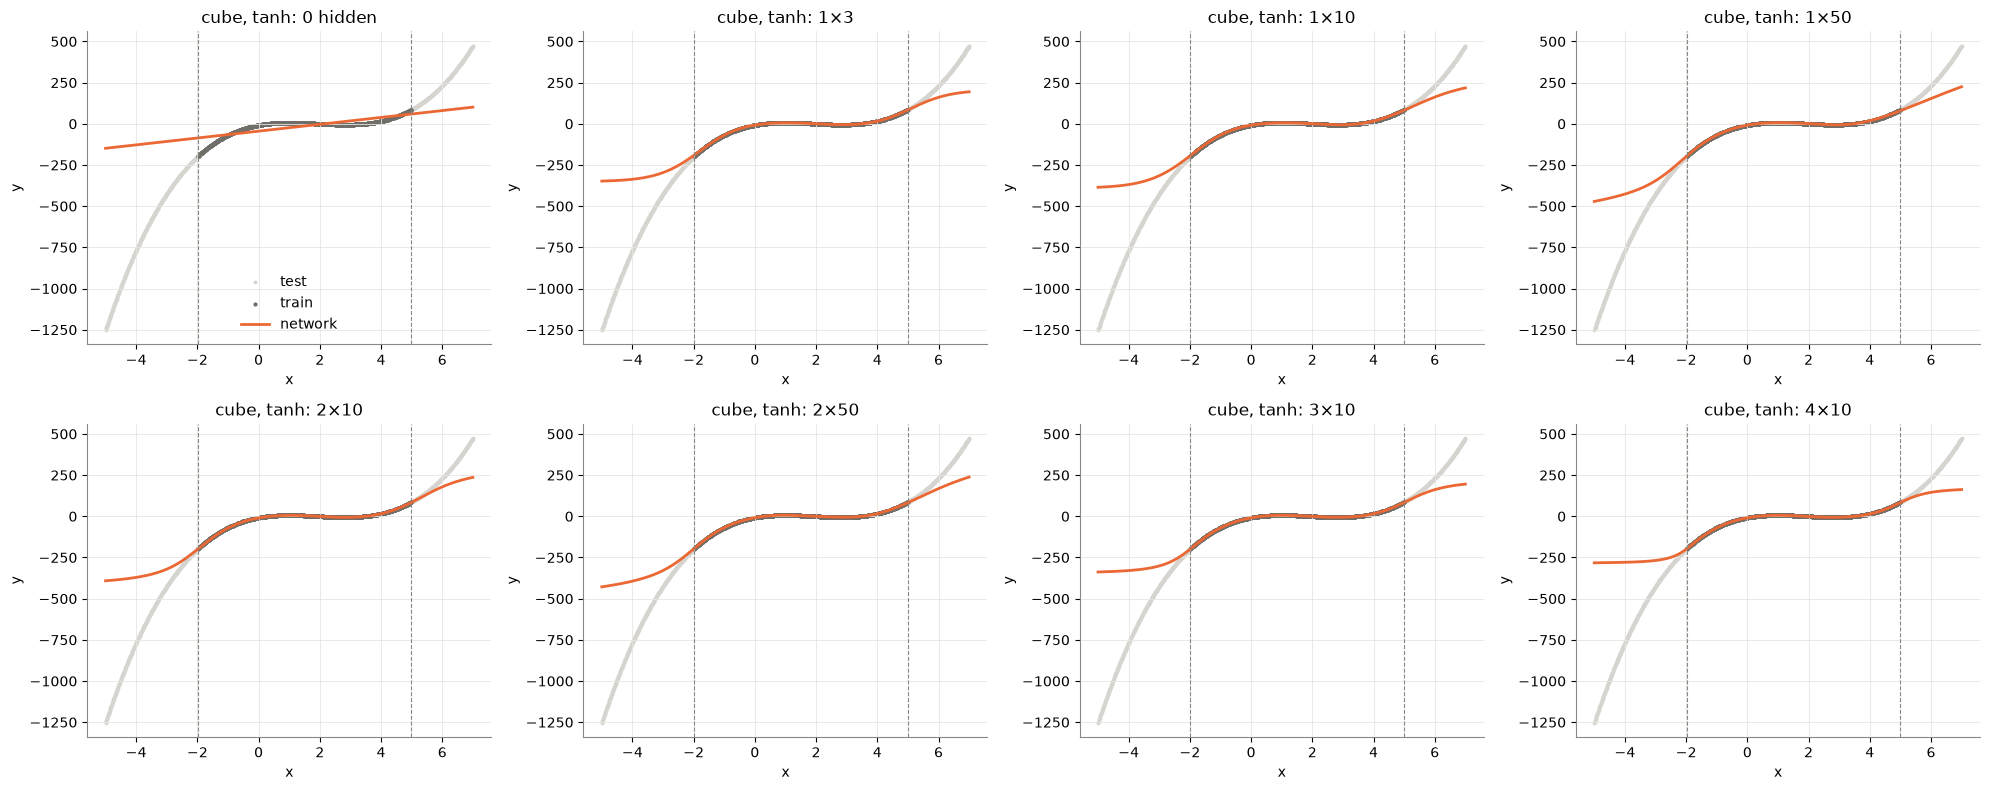

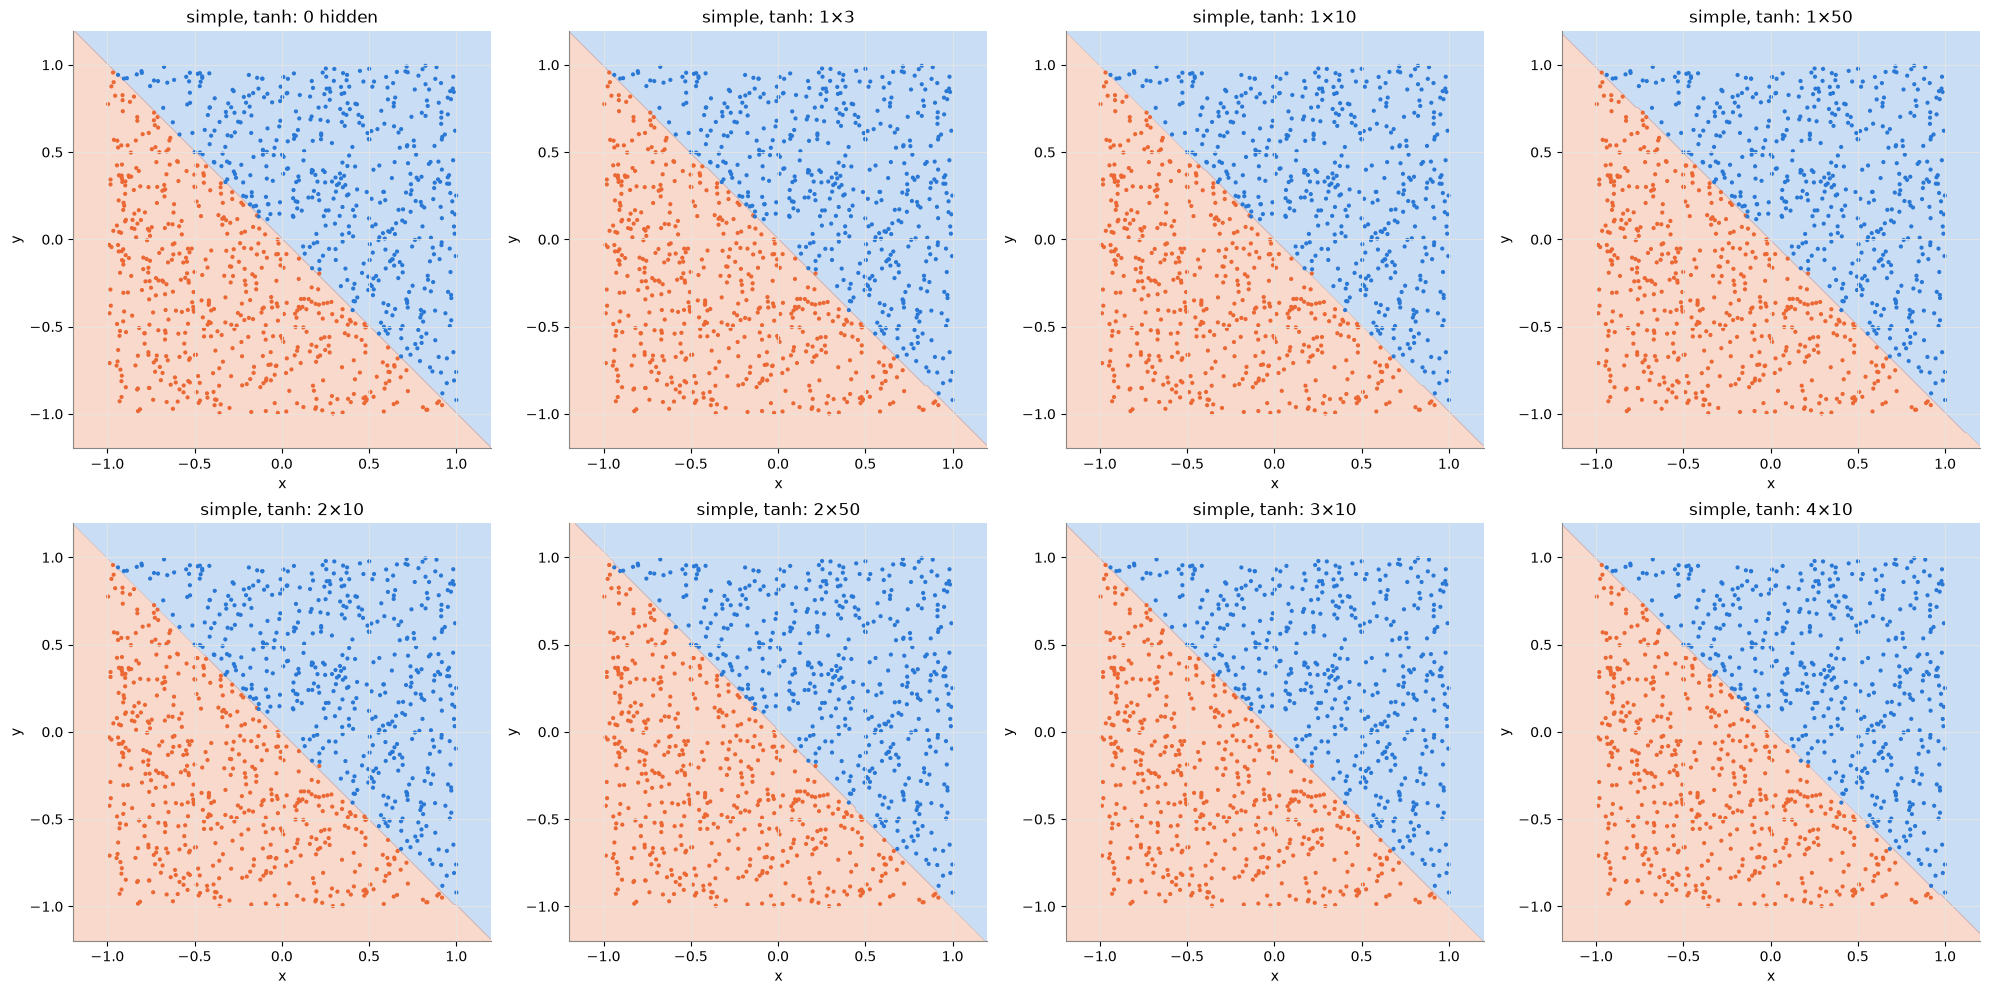

In [12]:
DEPTHS = ["0 hidden", "1×10", "2×10", "3×10", "4×10"]
fig, axes = plt.subplots(2, len(DEPTHS), figsize=(22, 7), sharey="row")
for row, name in zip(axes, REG_SETS):
    for ax, arch in zip(row, DEPTHS):
        for act_name in ACTIVATIONS:
            plot_loss(ax, e2_runs[name, arch, act_name][1], label=act_name, color=ACT_COLORS[act_name])
        ax.set_title(f"{name}: {arch}")
axes[0, 0].legend()
fig.tight_layout()
fig.savefig("figures/e2_loss_by_depth.png")
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, arch in zip(axes.ravel(), ARCHITECTURES):
    show_fit(ax, e2_runs["cube", arch, "tanh"][0], reg_data["cube"], f"cube, tanh: {arch}", ACT_COLORS["tanh"])
axes[0, 0].legend()
fig.tight_layout()
fig.savefig("figures/e2_cube_fits_tanh.png")
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for ax, arch in zip(axes.ravel(), ARCHITECTURES):
    show_regions(ax, e2_runs["simple", arch, "tanh"][0], cls_data["simple"], f"simple, tanh: {arch}")
fig.tight_layout()
fig.savefig("figures/e2_simple_regions_tanh.png")
plt.show()

### Sigmoida 4×10: dłuższe uczenie

Ta sama sieć co w eksperymencie 2 (`cube`, seed 0), uczona 3000 epok zamiast 1000.

RMSE train after 1000 epochs: 51.43, after 3000 epochs: 1.62


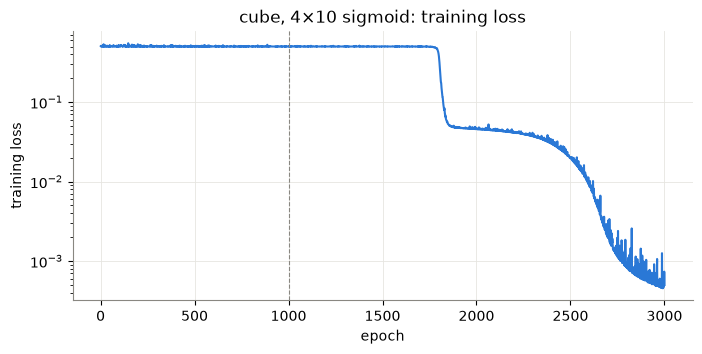

In [ ]:
d = reg_data["cube"]
net = MLP([1, 10, 10, 10, 10, 1], sigmoid, linear, mse, SEEDS[0])
history = net.train(d["X_train_n"], d["Y_train_n"], EPOCHS_REG, LR, BATCH)
rmse_1000 = reg_metrics(net, d)["RMSE train"]
history_more = net.train(d["X_train_n"], d["Y_train_n"], 2 * EPOCHS_REG, LR, BATCH)   # continues the same run
print(f"RMSE train after {EPOCHS_REG} epochs: {rmse_1000:.2f}, after {3 * EPOCHS_REG} epochs: {reg_metrics(net, d)['RMSE train']:.2f}")

fig, ax = plt.subplots(figsize=(8, 3.5))
plot_loss(ax, {"loss": history["loss"] + history_more["loss"]}, color=ACT_COLORS["sigmoid"])
ax.axvline(EPOCHS_REG, c="#898781", ls="--", lw=0.8)
ax.set_title("cube, 4×10 sigmoid: training loss")
fig.savefig("figures/e2_sigmoid_long.png")
plt.show()

### ReLU: martwe neurony

Neuron jest martwy, jeśli jego wyjście wynosi 0 dla całego zbioru uczącego. Liczba martwych neuronów w każdej
warstwie ukrytej dla sieci ReLU 1×3 (regresja) i 4×10 (`simple`).

In [ ]:
def dead_neurons(net, X):
    # per hidden layer: neurons whose output is 0 for every training point
    hidden = net.forward(X)[1][1:-1]
    return [int(np.all(a <= 0, axis=1).sum()) for a in hidden]


rows = []
for name, d in reg_data.items():
    for seed in SEEDS:
        net, _ = train_reg(d, [3], relu, seed=seed)
        rows.append({"network": f"{name}, 1×3", "seed": seed, "dead per hidden layer": dead_neurons(net, d["X_train_n"]),
                     "RMSE train": round(reg_metrics(net, d)["RMSE train"], 2)})
d = cls_data["simple"]
for seed in SEEDS:
    net, _ = train_cls(d, [10, 10, 10, 10], relu, seed=seed)
    rows.append({"network": "simple, 4×10", "seed": seed, "dead per hidden layer": dead_neurons(net, d["X_train"]),
                 "accuracy test": round(cls_metrics(net, d)["accuracy test"], 4)})
dead = pd.DataFrame(rows)
dead.to_csv("results/e2_dead_relu.csv", index=False)
display(dead)

,network,seed,dead per hidden layer,RMSE train,accuracy test
0,"cube, 1×3",0,[0],13.58,NaN
1,"cube, 1×3",1,[1],30.31,NaN
2,"cube, 1×3",2,[3],51.54,NaN
3,"activation, 1×3",0,[0],4.22,NaN
4,"activation, 1×3",1,[1],26.87,NaN
5,"activation, 1×3",2,[3],89.38,NaN
6,"simple, 4×10",0,"[1, 0, 2, 1]",NaN,0.989
7,"simple, 4×10",1,"[0, 0, 1, 10]",NaN,0.492
8,"simple, 4×10",2,"[0, 1, 3, 7]",NaN,0.994


## Eksperyment 3: miara błędu

2 warstwy ukryte \* 10 neuronów tanh. Regresja: MSE i MAE (wyjście liniowe). Klasyfikacja: softmax + entropia
krzyżowa oraz sigmoida + MSE. RMSE i dokładność (accuracy) na zbiorze uczącym jest mierzona 25 razy
w trakcie uczenia.

In [13]:
REG_LOSSES = {"MSE": mse, "MAE": mae}
CLS_LOSSES = {"softmax + cross-entropy": (softmax, cross_entropy), "sigmoid + MSE": (sigmoid, mse)}
E3_HIDDEN = [10, 10]
CHECKPOINTS = 25


def mae_orig(pred, Y):
    return np.mean(np.abs(pred - Y))


def learning_curve(net, X, Y, epochs, metric):
    step = epochs // CHECKPOINTS
    points = []
    for epoch in range(step, epochs + 1, step):
        net.train(X, Y, step, LR, BATCH)
        points.append((epoch, metric(net)))
    return np.array(points)


rows_reg, rows_cls, e3_curves = [], [], {}
start = time.time()
for name, d in reg_data.items():
    for loss_name, loss in REG_LOSSES.items():
        curves = []
        for seed in SEEDS:
            net = MLP([1, *E3_HIDDEN, 1], tanh, linear, loss, seed)
            curves.append(learning_curve(net, d["X_train_n"], d["Y_train_n"], EPOCHS_REG,
                                         lambda n: rmse(predict_reg(n, d, d["X_train_n"]), d["Y_train"])))
            pred_train = predict_reg(net, d, d["X_train_n"])
            rows_reg.append({"dataset": name, "loss": loss_name, "seed": seed, **reg_metrics(net, d),
                             "MAE train": mae_orig(pred_train, d["Y_train"])})
        e3_curves[name, loss_name] = np.mean(curves, axis=0)
for name, d in cls_data.items():
    K = d["Y_train"].shape[0]
    for loss_name, (output, loss) in CLS_LOSSES.items():
        curves = []
        for seed in SEEDS:
            net = MLP([2, *E3_HIDDEN, K], tanh, output, loss, seed)
            curves.append(learning_curve(net, d["X_train"], d["Y_train"], EPOCHS_CLS,
                                         lambda n: accuracy(n, d["X_train"], d["Y_train"])))
            rows_cls.append({"dataset": name, "loss": loss_name, "seed": seed, **cls_metrics(net, d)})
        e3_curves[name, loss_name] = np.mean(curves, axis=0)
print(f"{time.time() - start:.0f} s")

e3_reg = summarize(rows_reg, ["dataset", "loss"])
e3_cls = summarize(rows_cls, ["dataset", "loss"])
e3_reg.to_csv("results/e3_loss_regression.csv")
e3_cls.to_csv("results/e3_loss_classification.csv")
display(e3_reg.round(2), e3_cls.round(4))

18 s


RMSE train  RMSE test (train x-range)  RMSE test (all)  \
dataset    loss                                                           
cube       MSE         0.99                       1.01           204.17   
           MAE         6.76                       6.89           276.15   
activation MSE         0.42                       0.42             1.49   
           MAE         8.22                       8.28            15.05   

                 MAE train  
dataset    loss             
cube       MSE        0.73  
           MAE        5.65  
activation MSE        0.36  
           MAE        7.69

accuracy train  accuracy test
dataset     loss                                                  
simple      softmax + cross-entropy          0.9923         0.9897
            sigmoid + MSE                    0.9960         0.9950
three_gauss softmax + cross-entropy          0.9344         0.9359
            sigmoid + MSE                    0.9334         0.9311

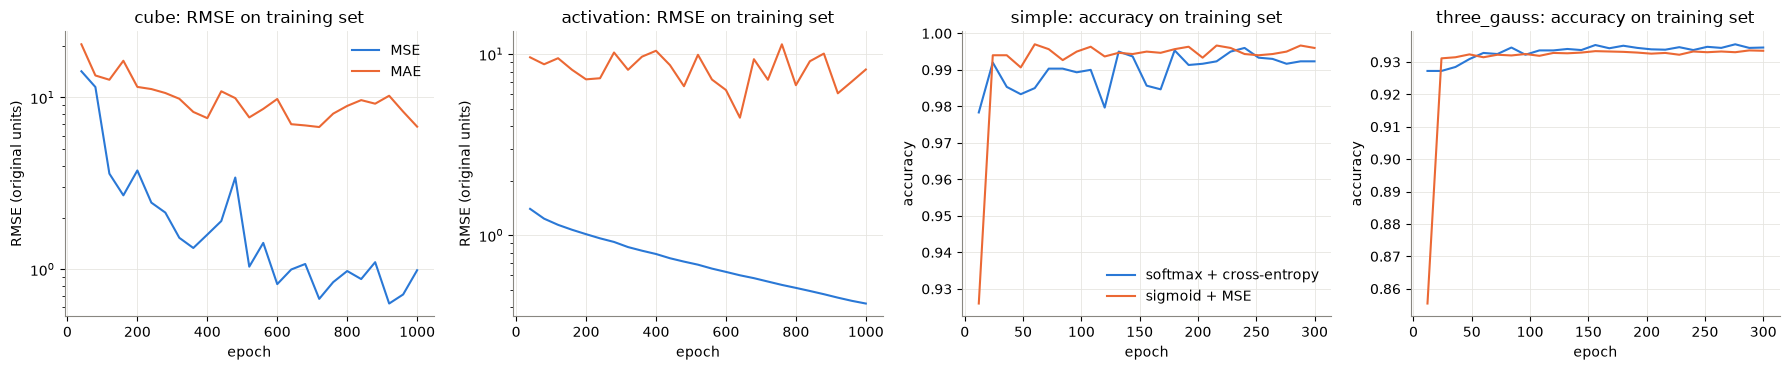

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, name in zip(axes[:2], REG_SETS):
    for (loss_name, color) in zip(REG_LOSSES, SERIES):
        curve = e3_curves[name, loss_name]
        ax.plot(curve[:, 0], curve[:, 1], c=color, label=loss_name)
    ax.set_yscale("log")
    ax.set_title(f"{name}: RMSE on training set")
    ax.set_ylabel("RMSE (original units)")
for ax, name in zip(axes[2:], CLS_SETS):
    for (loss_name, color) in zip(CLS_LOSSES, SERIES):
        curve = e3_curves[name, loss_name]
        ax.plot(curve[:, 0], curve[:, 1], c=color, label=loss_name)
    ax.set_title(f"{name}: accuracy on training set")
    ax.set_ylabel("accuracy")
for ax in axes:
    ax.set_xlabel("epoch")
axes[0].legend()
axes[2].legend()
fig.tight_layout()
fig.savefig("figures/e3_learning_curves.png")
plt.show()

### MAE i współczynnik uczenia

`cube`, 2 \* 10 tanh, seed 0, 1000 epok, różne wartości współczynnika uczenia.

In [ ]:
d = reg_data["cube"]
rows = []
for loss_name, loss in REG_LOSSES.items():
    for lr in [0.1, 0.03, 0.01]:
        net = MLP([1, *E3_HIDDEN, 1], tanh, linear, loss, SEEDS[0])
        net.train(d["X_train_n"], d["Y_train_n"], EPOCHS_REG, lr, BATCH)
        pred_train = predict_reg(net, d, d["X_train_n"])
        rows.append({"loss": loss_name, "lr": lr, "RMSE train": rmse(pred_train, d["Y_train"]),
                     "MAE train": mae_orig(pred_train, d["Y_train"])})
lr_table = pd.DataFrame(rows)
lr_table.to_csv("results/e3_mae_learning_rate.csv", index=False)
display(lr_table.round(2))

,loss,lr,RMSE train,MAE train
0,MSE,0.10,1.66,1.21
1,MSE,0.03,1.39,1.13
2,MSE,0.01,5.32,3.91
3,MAE,0.10,9.65,8.35
4,MAE,0.03,5.84,4.17
5,MAE,0.01,4.06,3.28


# Eksperymenty - Część druga

MNIST: oficjalny zbiór uczący (60 000 obrazów 28×28) podzielony losowo (ziarno `SPLIT_SEED`) na część uczącą (50 000) i walidacyjną (10 000). Zbiór testowy (10 000) używany tylko do końcowej oceny. Piksele przeskalowane do [0, 1].

In [ ]:
MNIST = "data/mnist"
N_VAL = 10_000
SPLIT_SEED = 0


def load_mnist_split():
    X, Y = load_mnist(f"{MNIST}/train-images-idx3-ubyte.gz", f"{MNIST}/train-labels-idx1-ubyte.gz")
    X_test, Y_test = load_mnist(f"{MNIST}/t10k-images-idx3-ubyte.gz", f"{MNIST}/t10k-labels-idx1-ubyte.gz")
    order = np.random.default_rng(SPLIT_SEED).permutation(X.shape[1])
    val, train = order[:N_VAL], order[N_VAL:]
    return dict(X_train=X[:, train], Y_train=Y[:, train], X_val=X[:, val], Y_val=Y[:, val],
                X_test=X_test, Y_test=Y_test)


mnist = load_mnist_split()
for part in ["train", "val", "test"]:
    X_part, Y_part = mnist[f"X_{part}"], mnist[f"Y_{part}"]
    print(f"{part:5} X {X_part.shape}  Y {Y_part.shape}  pixels {X_part.min():.0f}-{X_part.max():.0f}  "
          f"images per digit {Y_part.sum(axis=1).astype(int)}")

train X (784, 50000)  Y (10, 50000)  pixels 0-1  images per digit [4928 5635 5012 5119 4876 4485 4930 5235 4857 4923]
val   X (784, 10000)  Y (10, 10000)  pixels 0-1  images per digit [ 995 1107  946 1012  966  936  988 1030  994 1026]
test  X (784, 10000)  Y (10, 10000)  pixels 0-1  images per digit [ 980 1135 1032 1010  982  892  958 1028  974 1009]


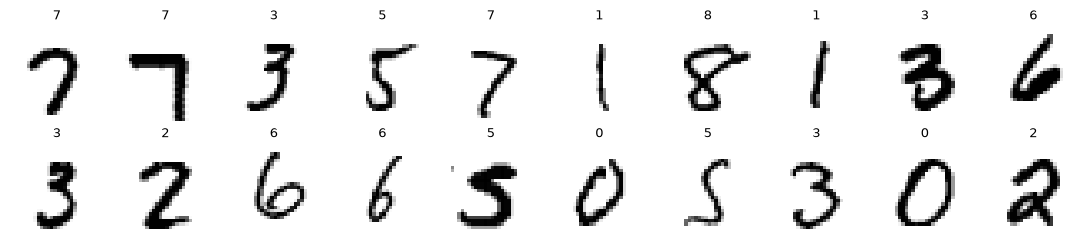

In [ ]:
fig = plot_digits(mnist["X_train"][:, :20], mnist["Y_train"][:, :20].argmax(axis=0))
fig.savefig("figures/mnist_examples.png")
plt.show()

## Pierwsza sieć

[784, 128, 10], tanh, softmax + entropia krzyżowa, η = 0.1, batch 32, 10 epok, ziarno 0. Dokładność na zbiorze uczącym i walidacyjnym po każdej epoce.

In [ ]:
EPOCHS_MNIST = 10


def train_mnist(hidden, activation, seed=0, epochs=EPOCHS_MNIST, lr=LR, batch=BATCH):
    net = MLP([784, *hidden, 10], activation, softmax, cross_entropy, seed)
    history = {"loss": [], "accuracy train": [], "accuracy val": []}
    for _ in range(epochs):
        history["loss"] += net.train(mnist["X_train"], mnist["Y_train"], 1, lr, batch)["loss"]
        history["accuracy train"].append(accuracy(net, mnist["X_train"], mnist["Y_train"]))
        history["accuracy val"].append(accuracy(net, mnist["X_val"], mnist["Y_val"]))
    return net, history

3 s, accuracy train 0.9909, val 0.9691


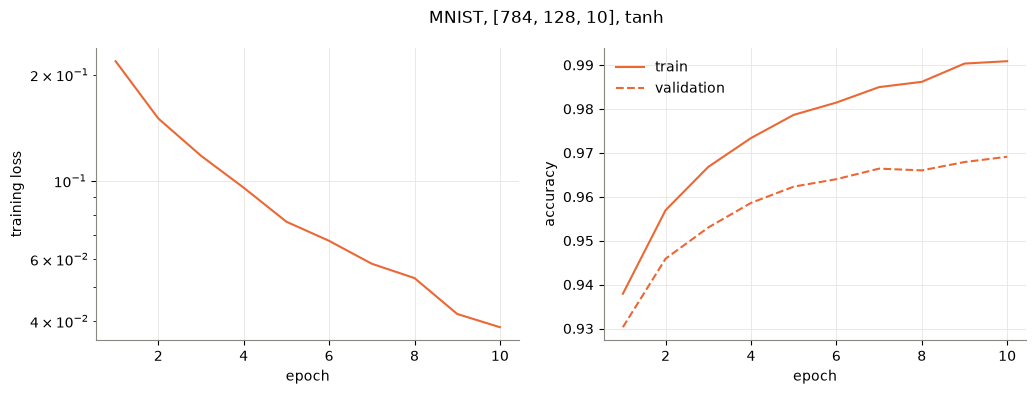

In [ ]:
start = time.time()
net, history = train_mnist([128], tanh)
print(f"{time.time() - start:.0f} s, accuracy train {history['accuracy train'][-1]:.4f}, val {history['accuracy val'][-1]:.4f}")

epochs = np.arange(1, EPOCHS_MNIST + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
plot_loss(axes[0], history, color=ACT_COLORS["tanh"])
axes[1].plot(epochs, history["accuracy train"], c=ACT_COLORS["tanh"], label="train")
axes[1].plot(epochs, history["accuracy val"], c=ACT_COLORS["tanh"], ls="--", label="validation")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("accuracy")
axes[1].legend()
fig.suptitle("MNIST, [784, 128, 10], tanh")
fig.savefig("figures/mnist_first.png")
plt.show()

## Funkcja aktywacji

[784, 128, 10], sigmoid / tanh / ReLU, 30 epok, ziarna 0, 1, 2 (średnia). Porównanie na zbiorze walidacyjnym.

In [ ]:
EPOCHS_SEARCH = 30


def n_params(hidden):
    sizes = [784, *hidden, 10]
    return sum((n_in + 1) * n_out for n_in, n_out in zip(sizes, sizes[1:]))


def run_mnist(configs):
    rows, curves = [], {}
    for name, (hidden, activation) in configs.items():
        histories, times = [], []
        for seed in SEEDS:
            start = time.time()
            histories.append(train_mnist(hidden, activation, seed=seed, epochs=EPOCHS_SEARCH)[1])
            times.append(time.time() - start)
        curve = {key: np.mean([h[key] for h in histories], axis=0) for key in histories[0]}
        best = int(curve["accuracy val"].argmax())
        rows.append({"network": name, "parameters": n_params(hidden),
                     "accuracy train": curve["accuracy train"][-1], "accuracy val": curve["accuracy val"][-1],
                     "best accuracy val": curve["accuracy val"][best], "best epoch": best + 1,
                     "time per run [s]": np.mean(times)})
        curves[name] = curve
    return pd.DataFrame(rows).set_index("network"), curves


def plot_mnist_curves(curves, colors, title):
    epochs = np.arange(1, EPOCHS_SEARCH + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    for name, curve in curves.items():
        plot_loss(axes[0], curve, label=name, color=colors[name])
        axes[1].plot(epochs, curve["accuracy val"], c=colors[name], label=name)
    axes[1].set_xlabel("epoch")
    axes[1].set_ylabel("validation accuracy")
    axes[1].legend()
    fig.suptitle(title)
    fig.tight_layout()
    return fig

,parameters,accuracy train,accuracy val,best accuracy val,best epoch,time per run [s]
network,,,,,,
sigmoid,101770,0.9875,0.9696,0.9698,29,11.2741
tanh,101770,0.9998,0.9722,0.9729,25,8.7924
relu,101770,0.9999,0.9740,0.9744,24,7.5067


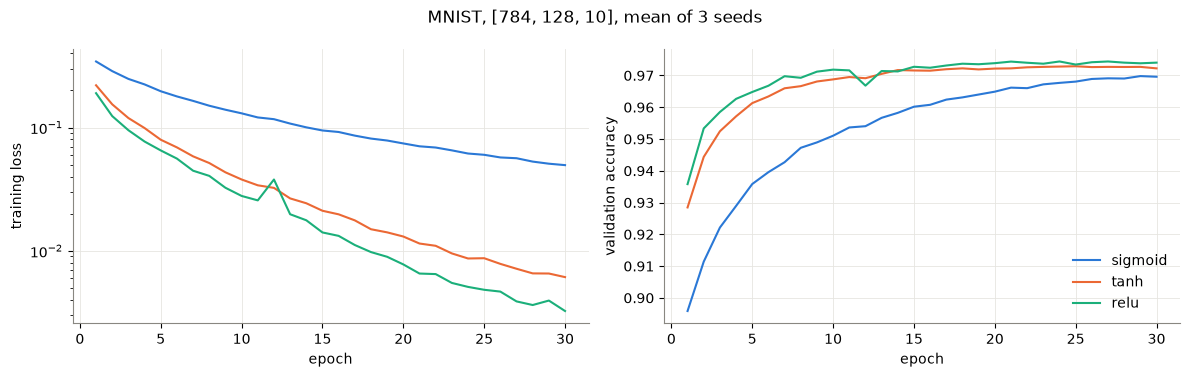

In [ ]:
act_table, act_curves = run_mnist({name: ([128], activation) for name, activation in ACTIVATIONS.items()})
act_table.to_csv("results/mnist_activation.csv")
display(act_table.round(4))
plot_mnist_curves(act_curves, ACT_COLORS, "MNIST, [784, 128, 10], mean of 3 seeds").savefig("figures/mnist_activation.png")
plt.show()

## Architektura

Funkcja aktywacji z najwyższą dokładnością walidacyjną z poprzedniego punktu, 1–3 warstwy ukryte, 30 epok, ziarna 0, 1, 2 (średnia).

activation: relu


,parameters,accuracy train,accuracy val,best accuracy val,best epoch,time per run [s]
network,,,,,,
[64],50890,0.9996,0.9711,0.9712,27,4.7092
[128],101770,0.9999,0.9740,0.9744,24,7.5363
[256],203530,1.0000,0.9758,0.9763,28,12.1385
"[256, 128]",235146,1.0000,0.9780,0.9780,28,15.1138
"[256, 128, 64]",242762,1.0000,0.9785,0.9788,24,16.1978


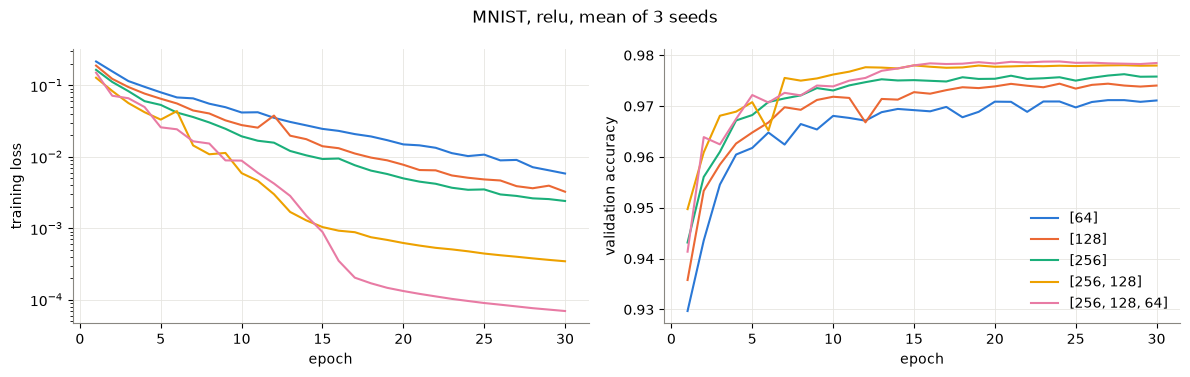

In [ ]:
BEST_ACTIVATION = act_table["best accuracy val"].idxmax()
ARCHITECTURES_MNIST = [[64], [128], [256], [256, 128], [256, 128, 64]]

arch_table, arch_curves = run_mnist({str(hidden): (hidden, ACTIVATIONS[BEST_ACTIVATION]) for hidden in ARCHITECTURES_MNIST})
arch_table.to_csv("results/mnist_architecture.csv")
print("activation:", BEST_ACTIVATION)
display(arch_table.round(4))
arch_colors = dict(zip(arch_curves, LINE_SERIES))
plot_mnist_curves(arch_curves, arch_colors, f"MNIST, {BEST_ACTIVATION}, mean of 3 seeds").savefig("figures/mnist_architecture.png")
plt.show()

## Sieć końcowa

[784, 256, 128, 64, 10], ReLU, softmax + entropia krzyżowa, η = 0.1, batch 32, 24 epoki, ziarno 0, podział zbioru uczącego z ziarnem `SPLIT_SEED` = 0. Uczenie na 50 000 obrazach, zbiór testowy użyty jednokrotnie do oceny.

In [ ]:
FINAL = {"hidden": [256, 128, 64], "activation": "relu", "lr": 0.1, "batch": 32, "epochs": 24, "seed": 0}

start = time.time()
final_net, final_history = train_mnist(FINAL["hidden"], ACTIVATIONS[FINAL["activation"]], seed=FINAL["seed"],
                                       epochs=FINAL["epochs"], lr=FINAL["lr"], batch=FINAL["batch"])
final_metrics = {f"accuracy {part}": accuracy(final_net, mnist[f"X_{part}"], mnist[f"Y_{part}"])
                 for part in ["train", "val", "test"]}
print(f"{time.time() - start:.0f} s")
final_table = pd.DataFrame([{**FINAL, "hidden": str(FINAL["hidden"]), "split seed": SPLIT_SEED, **final_metrics}])
final_table.to_csv("results/mnist_final.csv", index=False)
np.savez("results/mnist_final_weights.npz", **{f"W{l + 1}": W for l, W in enumerate(final_net.weights)},
         **{f"b{l + 1}": b for l, b in enumerate(final_net.biases)})
display(final_table.round(4))

13 s


,hidden,activation,lr,batch,epochs,seed,split seed,accuracy train,accuracy val,accuracy test
0,"[256, 128, 64]",relu,0.1,32,24,0,0,1.0,0.9785,0.9795


,test images,correct,accuracy
digit,,,
0,980,968,0.9878
1,1135,1125,0.9912
2,1032,1008,0.9767
3,1010,990,0.9802
4,982,961,0.9786
5,892,870,0.9753
6,958,939,0.9802
7,1028,1004,0.9767
8,974,949,0.9743


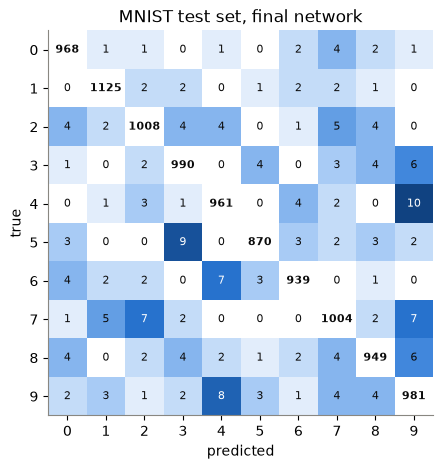

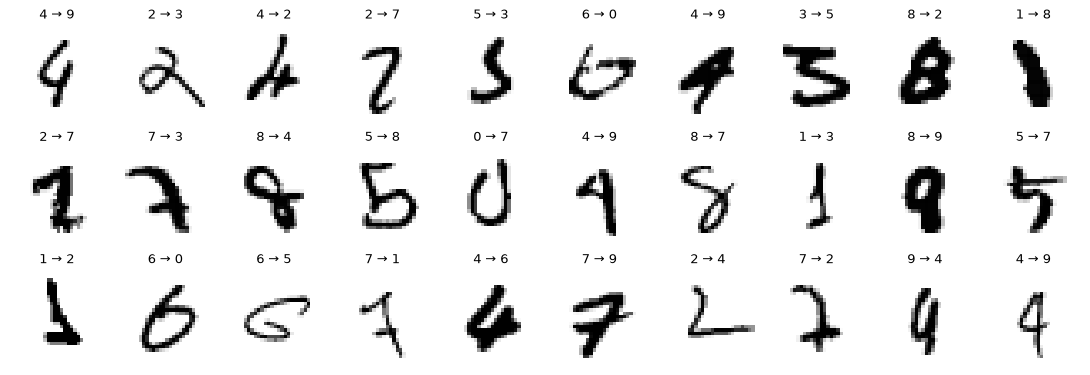

In [ ]:
true = mnist["Y_test"].argmax(axis=0)
pred = final_net.predict(mnist["X_test"]).argmax(axis=0)
confusion = mnist["Y_test"] @ np.eye(10)[pred]

per_digit = pd.DataFrame({"test images": confusion.sum(axis=1), "correct": np.diag(confusion)}).astype(int)
per_digit["accuracy"] = per_digit["correct"] / per_digit["test images"]
per_digit.index.name = "digit"
per_digit.to_csv("results/mnist_final_per_digit.csv")
display(per_digit.round(4))

fig, ax = plt.subplots(figsize=(5.5, 5))
plot_confusion(ax, confusion, "MNIST test set, final network")
fig.savefig("figures/mnist_confusion.png")
plt.show()

wrong = np.flatnonzero(pred != true)[:30]
fig = plot_digits(mnist["X_test"][:, wrong], [f"{t} → {p}" for t, p in zip(true[wrong], pred[wrong])])
fig.savefig("figures/mnist_misclassified.png")
plt.show()